In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
file_path = "../data/processed/nse_stocks_processed.csv"

df = pd.read_csv(file_path)

df["date"] = pd.to_datetime(df["date"])

df.head()

,date,symbol,open,high,low,close,adj_close,volume,daily_return,log_return,...,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
0,2017-03-15,HDFCBANK,352.737488,355.000000,352.637512,354.149994,322.995026,4271860,0.004182,0.004174,...,326.772249,0.034354,0.070173,0.163776,0.021930,0.081209,0.0,26102606.8,0.163656,0.043742
1,2017-03-16,HDFCBANK,354.524994,355.712494,353.412506,354.337494,323.166046,4980108,0.000529,0.000529,...,327.873499,0.043742,0.070415,0.163818,0.018065,0.081039,0.0,26229309.2,0.189868,0.041542
2,2017-03-17,HDFCBANK,354.637512,356.875000,353.212494,356.462494,325.104065,3390464,0.005997,0.005979,...,329.053248,0.041542,0.044430,0.163148,0.022701,0.078392,0.0,26092485.4,0.129940,0.045417
3,2017-03-20,HDFCBANK,356.662506,359.962494,356.487488,359.024994,327.441101,8142344,0.007189,0.007163,...,330.306248,0.045417,0.036086,0.163586,0.025712,0.081482,0.0,26247417.6,0.310215,0.040547
4,2017-03-21,HDFCBANK,358.500000,361.250000,358.500000,360.237488,328.546997,5557280,0.003377,0.003371,...,331.579998,0.040547,0.035479,0.109982,0.021443,0.046403,0.0,6412283.6,0.866662,0.089630


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nStocks:")
print(df["symbol"].unique())

print("\nMissing Values:")
print(df.isnull().sum().sum())

Shape: (18744, 25)

Columns:
['date', 'symbol', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'volatility_5d', 'volatility_10d', 'volatility_20d', 'momentum_5d', 'momentum_20d', 'drawdown', 'volume_ma_20', 'volume_ratio', 'target_5d_volatility']

Stocks:
['HDFCBANK' 'ICICIBANK' 'INFY' 'ITC' 'LT' 'RELIANCE' 'SBIN' 'TCS']

Missing Values:
0


In [4]:
features = [
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5",
    "volatility_10",
    "volatility_20",
    "momentum_5",
    "momentum_20",
    "drawdown"
]

features = [
    col for col in features
    if col in df.columns
]

target = "target_5d_volatility"

print("Features:")
print(features)

print("\nTarget:", target)

Features:
['daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'drawdown']

Target: target_5d_volatility


In [5]:
model_df = df[
    ["date", "symbol"] + features + [target]
].copy()

model_df = model_df.dropna()

model_df = model_df.sort_values(
    ["symbol", "date"]
).reset_index(drop=True)

print("Model Dataset Shape:", model_df.shape)
model_df.head()

Model Dataset Shape: (18744, 12)


,date,symbol,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,drawdown,target_5d_volatility
0,2017-03-15,HDFCBANK,0.004182,0.004174,0.004004,0.006671,350.689990,348.237494,345.869373,326.772249,0.0,0.043742
1,2017-03-16,HDFCBANK,0.000529,0.000529,-0.000529,0.006491,351.947491,348.879993,347.197498,327.873499,0.0,0.041542
2,2017-03-17,HDFCBANK,0.005997,0.005979,0.005146,0.010275,353.529993,350.023743,348.493123,329.053248,0.0,0.045417
3,2017-03-20,HDFCBANK,0.007189,0.007163,0.006624,0.009679,355.329993,351.501242,349.845622,330.306248,0.0,0.040547
4,2017-03-21,HDFCBANK,0.003377,0.003371,0.004847,0.007634,356.842493,353.006241,350.644371,331.579998,0.0,0.089630


In [6]:
print(model_df[target].describe())

count    18744.000000
mean         0.223860
std          0.149638
min          0.016310
25%          0.132857
50%          0.189265
75%          0.269226
max          1.852513
Name: target_5d_volatility, dtype: float64


In [7]:
train_parts = []
test_parts = []

for symbol, stock_data in model_df.groupby("symbol"):

    stock_data = stock_data.sort_values("date")

    split_index = int(len(stock_data) * 0.80)

    train_parts.append(
        stock_data.iloc[:split_index]
    )

    test_parts.append(
        stock_data.iloc[split_index:]
    )

train_df = pd.concat(train_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

print("Training Rows:", len(train_df))
print("Testing Rows:", len(test_df))

Training Rows: 14992
Testing Rows: 3752


In [8]:
print("Training Date Range:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting Date Range:")
print(test_df["date"].min(), "to", test_df["date"].max())

Training Date Range:
2017-03-15 00:00:00 to 2024-10-15 00:00:00

Testing Date Range:
2024-10-16 00:00:00 to 2026-09-01 00:00:00


In [9]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (14992, 9)
X_test: (3752, 9)


In [10]:
baseline_prediction = np.repeat(
    y_train.mean(),
    len(y_test)
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_prediction
    )
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 0.09506911066898731
Baseline RMSE: 0.11750054871231588


In [11]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression MAE: 0.07321850309447238
Linear Regression RMSE: 0.09598478243016917


In [12]:
coefficients = pd.DataFrame({
    "feature": features,
    "coefficient": linear_model.coef_
})

coefficients = coefficients.sort_values(
    by="coefficient",
    key=abs,
    ascending=False
)

coefficients

,feature,coefficient
0,daily_return,50.213543
1,log_return,-49.706203
3,price_range,5.898799
2,intraday_return,-0.509642
8,drawdown,-0.158039
7,ma_50,0.000141
5,ma_10,-0.000107
6,ma_20,-0.000086
4,ma_5,0.000051


In [13]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 0.07445237147304942
Random Forest RMSE: 0.09923546153032993


In [14]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
})

results

,Model,MAE,RMSE
0,Baseline,0.095069,0.117501
1,Linear Regression,0.073219,0.095985
2,Random Forest,0.074452,0.099235


In [15]:
results_path = "../data/processed/nse_stocks_initial_model_results.csv"

results.to_csv(
    results_path,
    index=False
)

print("Model results saved successfully!")
print(results_path)

Model results saved successfully!
../data/processed/nse_stocks_initial_model_results.csv


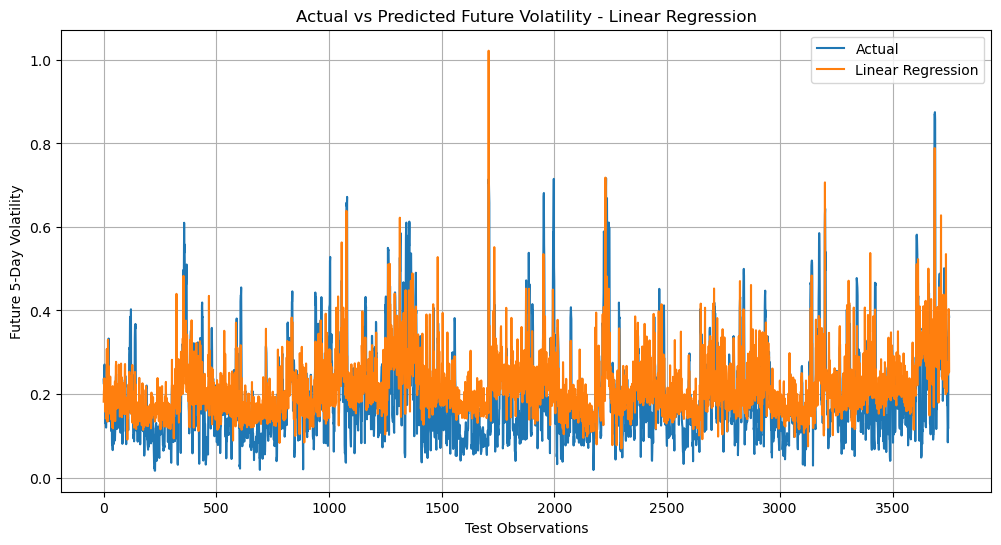

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    linear_predictions,
    label="Linear Regression"
)

plt.title("Actual vs Predicted Future Volatility - Linear Regression")
plt.xlabel("Test Observations")
plt.ylabel("Future 5-Day Volatility")
plt.legend()
plt.grid(True)

plt.show()

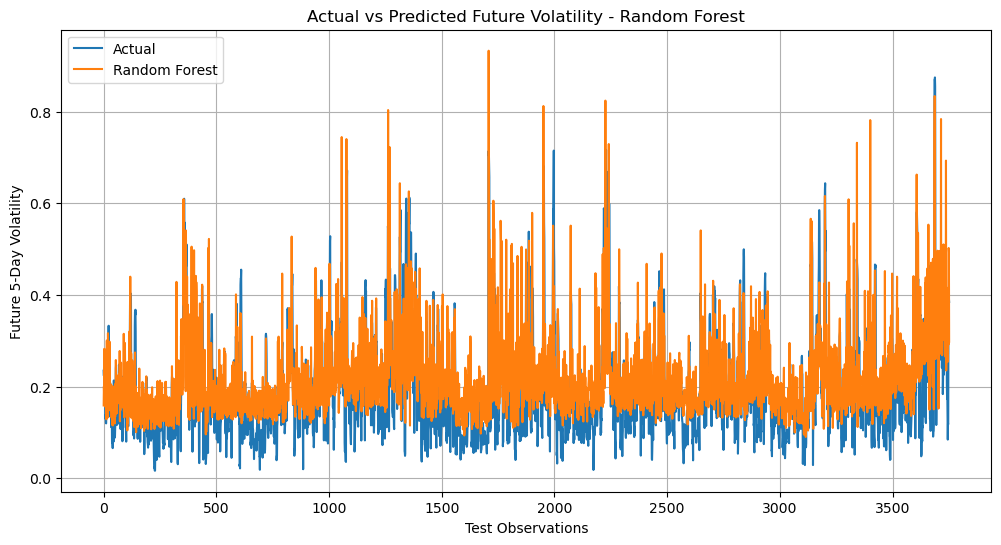

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    rf_predictions,
    label="Random Forest"
)

plt.title("Actual vs Predicted Future Volatility - Random Forest")
plt.xlabel("Test Observations")
plt.ylabel("Future 5-Day Volatility")
plt.legend()
plt.grid(True)

plt.show()

In [18]:
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
3,price_range,0.498711
8,drawdown,0.108895
2,intraday_return,0.073038
0,daily_return,0.066806
1,log_return,0.066223
7,ma_50,0.059275
4,ma_5,0.045680
6,ma_20,0.042821
5,ma_10,0.038552


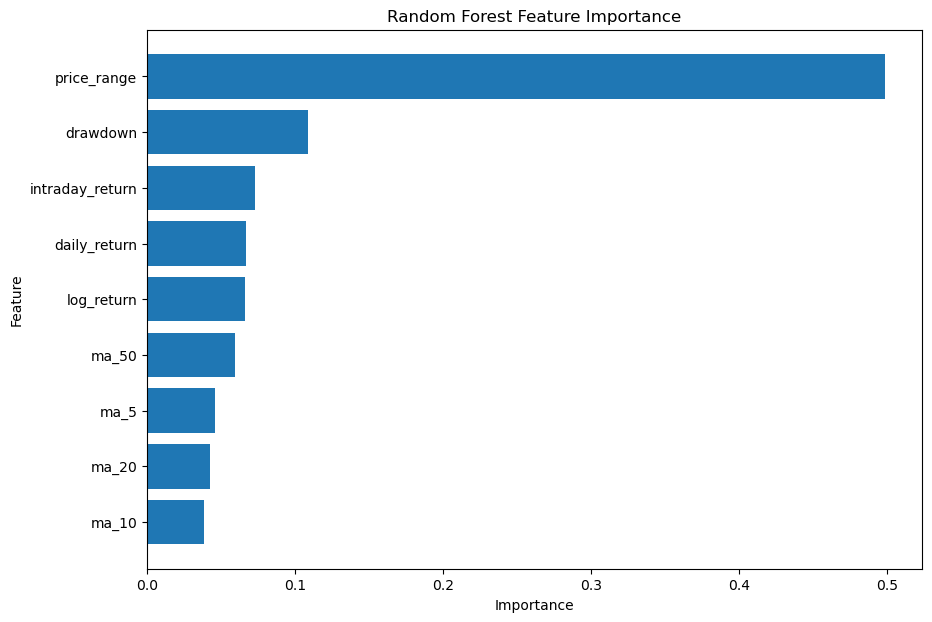

In [19]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [20]:
importance_path = "../data/processed/nse_stocks_random_forest_feature_importance.csv"

feature_importance.to_csv(
    importance_path,
    index=False
)

print("Feature importance saved successfully!")
print(importance_path)

Feature importance saved successfully!
../data/processed/nse_stocks_random_forest_feature_importance.csv


In [21]:
stock_results = []

for symbol in test_df["symbol"].unique():

    mask = test_df["symbol"] == symbol

    actual = y_test[mask]
    predicted = rf_predictions[mask]

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    stock_results.append({
        "symbol": symbol,
        "MAE": mae,
        "RMSE": rmse,
        "test_rows": mask.sum()
    })

stock_results_df = pd.DataFrame(stock_results)

stock_results_df

,symbol,MAE,RMSE,test_rows
0,HDFCBANK,0.063389,0.083125,469
1,ICICIBANK,0.056347,0.070883,469
2,INFY,0.089782,0.117037,469
3,ITC,0.083577,0.109203,469
4,LT,0.078053,0.106765,469
5,RELIANCE,0.060958,0.077808,469
6,SBIN,0.068228,0.090239,469
7,TCS,0.095284,0.125013,469


In [22]:
stock_results_path = "../data/processed/nse_stocks_model_results_by_stock.csv"

stock_results_df.to_csv(
    stock_results_path,
    index=False
)

print("Stock-wise model results saved!")
print(stock_results_path)

Stock-wise model results saved!
../data/processed/nse_stocks_model_results_by_stock.csv


In [23]:
print("NSE STOCKS INITIAL MODEL EXPERIMENT")
print("-----------------------------------")

print("\nModels Tested:")
print("1. Baseline")
print("2. Linear Regression")
print("3. Random Forest")

print("\nEvaluation Metrics:")
print("1. MAE")
print("2. RMSE")

print("\nTarget:")
print(target)

print("\nTraining Rows:", len(train_df))
print("Testing Rows:", len(test_df))

NSE STOCKS INITIAL MODEL EXPERIMENT
-----------------------------------

Models Tested:
1. Baseline
2. Linear Regression
3. Random Forest

Evaluation Metrics:
1. MAE
2. RMSE

Target:
target_5d_volatility

Training Rows: 14992
Testing Rows: 3752


In [24]:
results

,Model,MAE,RMSE
0,Baseline,0.095069,0.117501
1,Linear Regression,0.073219,0.095985
2,Random Forest,0.074452,0.099235


update kia h 5-d volatility uske baad wala scene h yeh

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance


In [2]:

df = pd.read_csv("../data/processed/nse_stocks_processed.csv")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Stocks:", df["symbol"].nunique())
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Target exists:", "target_5d_volatility" in df.columns)


Dataset shape: (18712, 25)
Stocks: 8
Date range: 2017-03-15 00:00:00 to 2026-08-26 00:00:00
Target exists: True


In [3]:

features = [
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5d",
    "volatility_10d",
    "volatility_20d",
    "momentum_5d",
    "momentum_20d",
    "drawdown"
]

target = "target_5d_volatility"

missing = [c for c in features + [target] if c not in df.columns]
print("Missing columns:", missing)


Missing columns: []


In [4]:

model_df = df[["date", "symbol"] + features + [target]].copy()

model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna(subset=features + [target])
model_df = model_df.sort_values(["symbol", "date"])

train_parts = []
test_parts = []

for symbol, group in model_df.groupby("symbol"):
    group = group.sort_values("date").reset_index(drop=True)

    split = int(len(group) * 0.80)
    train_end = split - 5

    if train_end <= 0 or split >= len(group):
        continue

    train_parts.append(group.iloc[:train_end])
    test_parts.append(group.iloc[split:])

train_df = pd.concat(train_parts, ignore_index=True)
test_df = pd.concat(test_parts, ignore_index=True)

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training date range:", train_df.date.min(), "to", train_df.date.max())
print("Testing date range:", test_df.date.min(), "to", test_df.date.max())


Training rows: 14928
Testing rows: 3744
Training date range: 2017-03-15 00:00:00 to 2024-10-03 00:00:00
Testing date range: 2024-10-11 00:00:00 to 2026-08-26 00:00:00


In [5]:

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)


Baseline MAE: 0.0951801187306015
Baseline RMSE: 0.117590677196787


In [6]:

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

results = [{
    "Model": "Mean Baseline",
    "MAE": mean_absolute_error(y_test, baseline_pred),
    "RMSE": np.sqrt(
        mean_squared_error(y_test, baseline_pred)
    )
}]

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("MAE")

print(results_df.to_string(index=False))


            Model      MAE     RMSE
      Extra Trees 0.079649 0.105705
Linear Regression 0.081273 0.107906
    Random Forest 0.081312 0.109322
 Ridge Regression 0.081846 0.107902
    Mean Baseline 0.095180 0.117591


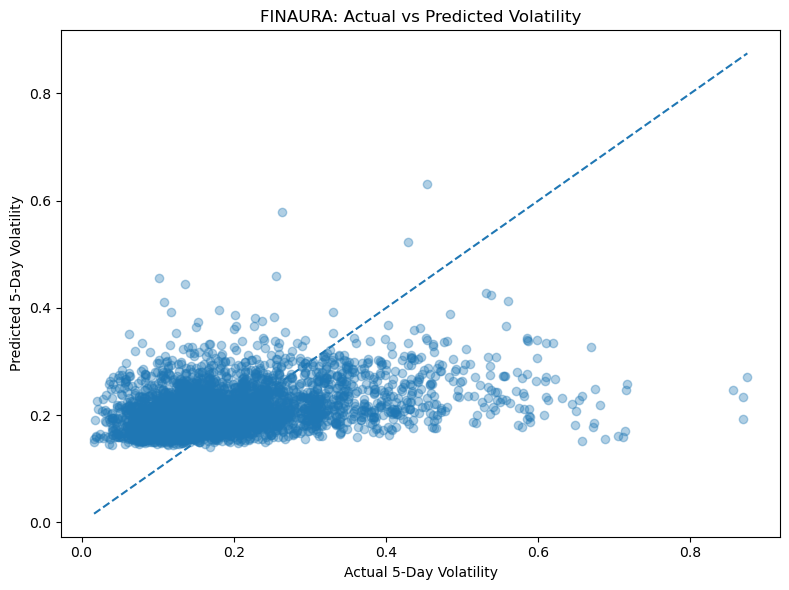

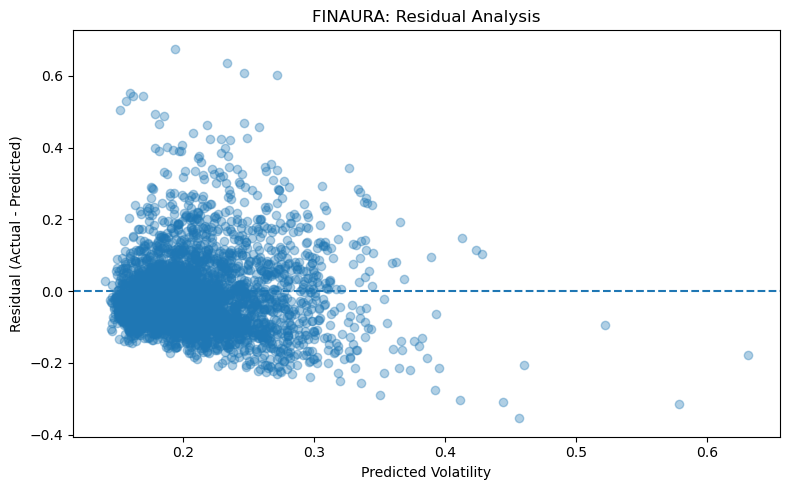

Mean residual: -0.016062655532990903
Residual standard deviation: 0.10449140887025274


In [7]:

# Actual vs Predicted using Extra Trees

best_model = models["Extra Trees"]
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions, alpha=0.35)

# Ideal prediction line
min_val = min(y_test.min(), best_predictions.min())
max_val = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual 5-Day Volatility")
plt.ylabel("Predicted 5-Day Volatility")
plt.title("FINAURA: Actual vs Predicted Volatility")
plt.tight_layout()
plt.show()


# Residual analysis
residuals = y_test - best_predictions

plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, residuals, alpha=0.35)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Volatility")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("FINAURA: Residual Analysis")
plt.tight_layout()
plt.show()

print("Mean residual:", residuals.mean())
print("Residual standard deviation:", residuals.std())


        Feature  Importance      Std
 volatility_20d    0.003364 0.000146
       drawdown    0.001390 0.000079
    price_range    0.001101 0.000168
   momentum_20d    0.000908 0.000120
  volatility_5d    0.000281 0.000037
          ma_20    0.000236 0.000040
 volatility_10d    0.000201 0.000100
          ma_50    0.000185 0.000040
intraday_return    0.000183 0.000016
           ma_5    0.000155 0.000031
          ma_10    0.000142 0.000020
     log_return    0.000077 0.000019
    momentum_5d    0.000028 0.000124
   daily_return    0.000023 0.000023


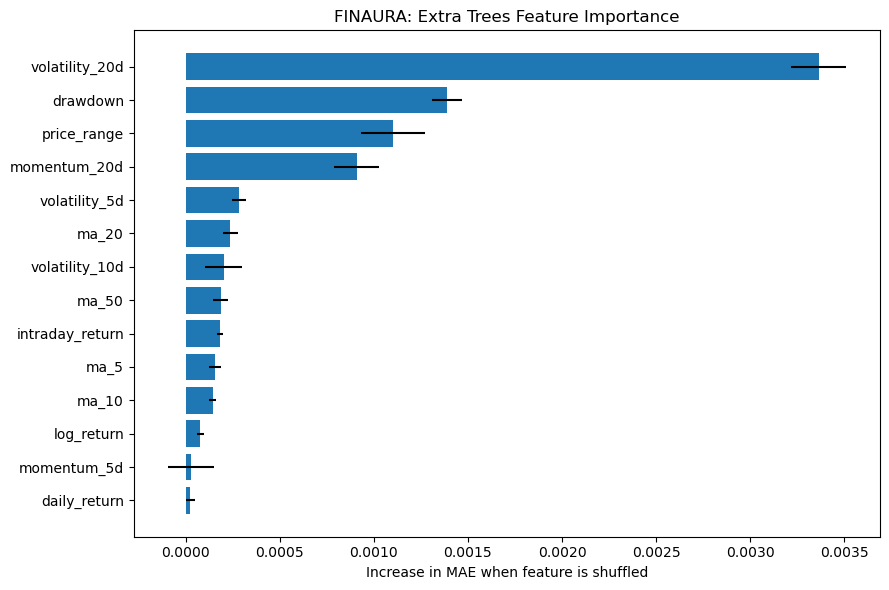

In [8]:

# Feature Importance using Permutation Importance

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

best_model = models["Extra Trees"]

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print(importance_df.to_string(index=False))

plt.figure(figsize=(9, 6))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1],
    xerr=importance_df["Std"][::-1]
)

plt.xlabel("Increase in MAE when feature is shuffled")
plt.title("FINAURA: Extra Trees Feature Importance")
plt.tight_layout()
plt.show()


In [9]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Highest 10% actual volatility cases
threshold = y_test.quantile(0.90)
high_risk_mask = y_test >= threshold

high_actual = y_test.loc[high_risk_mask]
high_predicted = best_predictions[high_risk_mask.to_numpy()]

print("High-volatility threshold:", threshold)
print("High-volatility test rows:", len(high_actual))

print(
    "High-volatility MAE:",
    mean_absolute_error(high_actual, high_predicted)
)

print(
    "High-volatility RMSE:",
    np.sqrt(mean_squared_error(high_actual, high_predicted))
)

print(
    "Mean actual volatility:",
    high_actual.mean()
)

print(
    "Mean predicted volatility:",
    high_predicted.mean()
)


High-volatility threshold: 0.34002716635493796
High-volatility test rows: 375
High-volatility MAE: 0.20336072326708107
High-volatility RMSE: 0.23081490279240655
Mean actual volatility: 0.44892092099018144
Mean predicted volatility: 0.24700332250563511


In [10]:

# Check chronological split integrity

print("Latest training date:", train_df["date"].max())
print("Earliest testing date:", test_df["date"].min())

print(
    "Overall date overlap:",
    train_df["date"].max() >= test_df["date"].min()
)

print("\nPer-stock split check:")

split_check = []

for symbol in sorted(set(train_df["symbol"]) & set(test_df["symbol"])):
    train_dates = train_df.loc[
        train_df["symbol"] == symbol, "date"
    ]
    test_dates = test_df.loc[
        test_df["symbol"] == symbol, "date"
    ]

    split_check.append({
        "symbol": symbol,
        "last_train_date": train_dates.max(),
        "first_test_date": test_dates.min(),
        "valid_order": train_dates.max() < test_dates.min()
    })

split_check_df = pd.DataFrame(split_check)
print(split_check_df.to_string(index=False))

print(
    "\nAll stocks chronologically ordered:",
    split_check_df["valid_order"].all()
)


Latest training date: 2024-10-03 00:00:00
Earliest testing date: 2024-10-11 00:00:00
Overall date overlap: False

Per-stock split check:
   symbol last_train_date first_test_date  valid_order
 HDFCBANK      2024-10-03      2024-10-11         True
ICICIBANK      2024-10-03      2024-10-11         True
     INFY      2024-10-03      2024-10-11         True
      ITC      2024-10-03      2024-10-11         True
       LT      2024-10-03      2024-10-11         True
 RELIANCE      2024-10-03      2024-10-11         True
     SBIN      2024-10-03      2024-10-11         True
      TCS      2024-10-03      2024-10-11         True

All stocks chronologically ordered: True


In [11]:

# Chronological train-validation split
# Final test set remains untouched.

train_df = train_df.sort_values(
    ["date", "symbol"]
).reset_index(drop=True)

validation_fraction = 0.20

validation_start = train_df["date"].quantile(
    1 - validation_fraction
)

# Remove training rows whose 5-day future target
# could extend into the validation period.
train_cutoff = validation_start

fit_df = train_df[train_df["date"] < train_cutoff].copy()
val_df = train_df[train_df["date"] >= validation_start].copy()

# Five-row embargo per stock at the boundary
fit_parts = []

for symbol, group in fit_df.groupby("symbol"):
    group = group.sort_values("date")
    fit_parts.append(group.iloc[:-5])

fit_df = pd.concat(fit_parts, ignore_index=True)

X_fit = fit_df[features]
y_fit = fit_df[target]

X_val = val_df[features]
y_val = val_df[target]

print("Fit rows:", len(fit_df))
print("Validation rows:", len(val_df))

print("Fit date range:",
      fit_df["date"].min(), "to", fit_df["date"].max())

print("Validation date range:",
      val_df["date"].min(), "to", val_df["date"].max())

print("Final test date range:",
      test_df["date"].min(), "to", test_df["date"].max())


Fit rows: 11896
Validation rows: 2992
Fit date range: 2017-03-15 00:00:00 to 2023-03-16 00:00:00
Validation date range: 2023-03-24 00:00:00 to 2024-10-03 00:00:00
Final test date range: 2024-10-11 00:00:00 to 2026-08-26 00:00:00


In [12]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

configs = [
    {"max_depth": 8,  "min_samples_leaf": 5},
    {"max_depth": 12, "min_samples_leaf": 5},
    {"max_depth": 16, "min_samples_leaf": 5},
    {"max_depth": None, "min_samples_leaf": 5},
    {"max_depth": 12, "min_samples_leaf": 10},
    {"max_depth": 16, "min_samples_leaf": 10},
]

tuning_results = []

for config in configs:
    model = ExtraTreesRegressor(
        n_estimators=200,
        max_depth=config["max_depth"],
        min_samples_leaf=config["min_samples_leaf"],
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_fit, y_fit)
    val_pred = model.predict(X_val)

    tuning_results.append({
        "max_depth": str(config["max_depth"]),
        "min_samples_leaf": config["min_samples_leaf"],
        "MAE": mean_absolute_error(y_val, val_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_val, val_pred)
        )
    })

tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values("MAE")

print(tuning_df.to_string(index=False))


max_depth  min_samples_leaf      MAE     RMSE
       12                10 0.081881 0.121233
        8                 5 0.081902 0.120938
       16                10 0.082129 0.121380
       12                 5 0.082158 0.121205
       16                 5 0.082927 0.121998
     None                 5 0.083101 0.122013


comparison with validation baseline 


In [13]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import ExtraTreesRegressor
import numpy as np
import pandas as pd

# Validation mean baseline
baseline_val = DummyRegressor(strategy="mean")
baseline_val.fit(X_fit, y_fit)

baseline_val_pred = baseline_val.predict(X_val)

# Best configuration by validation MAE
tuned_model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

tuned_model.fit(X_fit, y_fit)
tuned_val_pred = tuned_model.predict(X_val)

comparison = pd.DataFrame([
    {
        "Model": "Mean Baseline",
        "MAE": mean_absolute_error(y_val, baseline_val_pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, baseline_val_pred))
    },
    {
        "Model": "Tuned Extra Trees",
        "MAE": mean_absolute_error(y_val, tuned_val_pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, tuned_val_pred))
    }
])

print(comparison.to_string(index=False))


            Model      MAE     RMSE
    Mean Baseline 0.100662 0.131042
Tuned Extra Trees 0.081881 0.121233


Final model train + evaluate 

In [14]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.dummy import DummyRegressor
import numpy as np
import pandas as pd

# 1. Combine training and validation data
final_train_df = pd.concat(
    [fit_df, val_df],
    ignore_index=True
)

final_train_df = final_train_df.sort_values(
    ["date", "symbol"]
).reset_index(drop=True)

# 2. Remove last 5 rows of each stock
# to avoid incomplete future targets at the boundary
train_parts = []

for symbol, group in final_train_df.groupby("symbol"):
    group = group.sort_values("date")
    train_parts.append(group.iloc[:-5])

final_train_df = pd.concat(
    train_parts,
    ignore_index=True
)

# 3. Prepare training data
X_final_train = final_train_df[features]
y_final_train = final_train_df[target]

# 4. Prepare test data
X_test = test_df[features]
y_test = test_df[target]

# 5. Train tuned Extra Trees
final_model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_final_train, y_final_train)

# 6. Train mean baseline
final_baseline = DummyRegressor(strategy="mean")
final_baseline.fit(X_final_train, y_final_train)

# 7. Make predictions
model_predictions = final_model.predict(X_test)
baseline_predictions = final_baseline.predict(X_test)

# 8. Compare performance
results = pd.DataFrame([
    {
        "Model": "Mean Baseline",
        "MAE": mean_absolute_error(
            y_test, baseline_predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, baseline_predictions)
        )
    },
    {
        "Model": "Tuned Extra Trees",
        "MAE": mean_absolute_error(
            y_test, model_predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, model_predictions)
        )
    }
])

print("Training rows:", len(X_final_train))
print("Test rows:", len(X_test))
print("\nTest Period:")
print(test_df["date"].min(), "to", test_df["date"].max())

print("\nFinal Evaluation Results:")
print(results.to_string(index=False))


Training rows: 14848
Test rows: 3744

Test Period:
2024-10-11 00:00:00 to 2026-08-26 00:00:00

Final Evaluation Results:
            Model      MAE     RMSE
    Mean Baseline 0.095292 0.117664
Tuned Extra Trees 0.079940 0.106101


In [15]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual volatility ke 90th percentile ka threshold
# Training data se calculate hoga, test labels se nahi
high_vol_threshold = final_train_df[target].quantile(0.90)

# High-volatility test observations select karo
high_vol_mask = y_test >= high_vol_threshold

y_high = y_test.loc[high_vol_mask]
pred_high = model_predictions[high_vol_mask.to_numpy()]

print("High-volatility threshold:", high_vol_threshold)
print("High-volatility test rows:", len(y_high))

if len(y_high) > 0:
    print(
        "High-volatility MAE:",
        mean_absolute_error(y_high, pred_high)
    )
    print(
        "High-volatility RMSE:",
        np.sqrt(mean_squared_error(y_high, pred_high))
    )
    print("Mean actual volatility:", y_high.mean())
    print("Mean predicted volatility:", pred_high.mean())
else:
    print("No high-volatility test rows found.")


High-volatility threshold: 0.3895516644442787
High-volatility test rows: 251
High-volatility MAE: 0.24306084262552033
High-volatility RMSE: 0.26689538905928245
Mean actual volatility: 0.49144474139472677
Mean predicted volatility: 0.2500886192232524


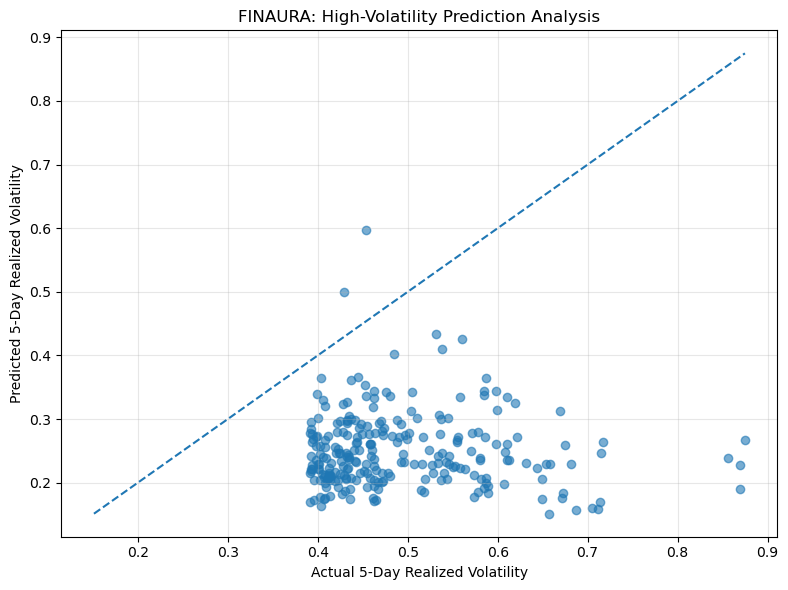

In [16]:

import matplotlib.pyplot as plt
import numpy as np

# High-volatility observations ke actual aur predicted values
actual_high = y_high.to_numpy()
predicted_high = np.asarray(pred_high)

plt.figure(figsize=(8, 6))

plt.scatter(
    actual_high,
    predicted_high,
    alpha=0.6
)

# Perfect prediction reference line
min_value = min(actual_high.min(), predicted_high.min())
max_value = max(actual_high.max(), predicted_high.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual 5-Day Realized Volatility")
plt.ylabel("Predicted 5-Day Realized Volatility")
plt.title("FINAURA: High-Volatility Prediction Analysis")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


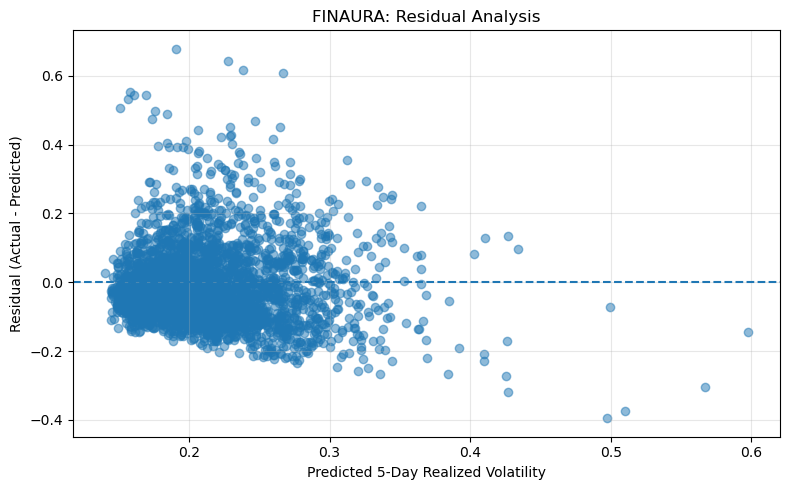

Mean residual: -0.016326766108079382
Residual standard deviation: 0.10483729152616916


In [17]:

import matplotlib.pyplot as plt
import numpy as np

# Test set ke saare predictions
actual = y_test.to_numpy()
predicted = np.asarray(model_predictions)

# Residual = Actual - Predicted
residuals = actual - predicted

plt.figure(figsize=(8, 5))

plt.scatter(
    predicted,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted 5-Day Realized Volatility")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("FINAURA: Residual Analysis")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Mean residual:", np.mean(residuals))
print("Residual standard deviation:", np.std(residuals))


In [18]:

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

error_df = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": np.asarray(model_predictions)
})

# Training data ke thresholds use karo
q1 = final_train_df[target].quantile(0.50)
q2 = final_train_df[target].quantile(0.90)

# Test observations ko volatility groups mein divide karo
error_df["volatility_group"] = np.select(
    [
        error_df["actual"] <= q1,
        error_df["actual"] <= q2
    ],
    [
        "Low / Moderate",
        "Elevated"
    ],
    default="High"
)

error_df["absolute_error"] = (
    error_df["actual"] - error_df["predicted"]
).abs()

error_df["residual"] = (
    error_df["actual"] - error_df["predicted"]
)

summary = error_df.groupby(
    "volatility_group",
    sort=False
).agg(
    Rows=("actual", "size"),
    Actual_Mean=("actual", "mean"),
    Predicted_Mean=("predicted", "mean"),
    MAE=("absolute_error", "mean"),
    Mean_Residual=("residual", "mean")
).reset_index()

print("Training median threshold:", q1)
print("Training 90th percentile threshold:", q2)
print("\nError analysis by volatility group:")
print(summary.round(4).to_string(index=False))


Training median threshold: 0.19591296428250898
Training 90th percentile threshold: 0.3895516644442787

Error analysis by volatility group:
volatility_group  Rows  Actual_Mean  Predicted_Mean    MAE  Mean_Residual
        Elevated  1189       0.2625          0.2224 0.0557         0.0401
  Low / Moderate  2304       0.1278          0.2013 0.0747        -0.0735
            High   251       0.4914          0.2501 0.2431         0.2414


In [19]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_final_train, y_final_train)

# Predictions
rf_predictions = rf_model.predict(X_test)

# Compare both models
comparison = pd.DataFrame([
    {
        "Model": "Tuned Extra Trees",
        "MAE": mean_absolute_error(y_test, model_predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, model_predictions)
        )
    },
    {
        "Model": "Random Forest",
        "MAE": mean_absolute_error(y_test, rf_predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, rf_predictions)
        )
    }
])

print(comparison.round(6).to_string(index=False))


            Model      MAE     RMSE
Tuned Extra Trees 0.079940 0.106101
    Random Forest 0.081348 0.108767


Feature Importance Ranking:
        Feature  Importance
   momentum_20d    0.201298
 volatility_20d    0.187358
 volatility_10d    0.169737
    price_range    0.101567
  volatility_5d    0.092671
       drawdown    0.082807
    momentum_5d    0.062517
          ma_20    0.020091
          ma_50    0.020010
          ma_10    0.019603
           ma_5    0.018960
   daily_return    0.008123
intraday_return    0.007763
     log_return    0.007496


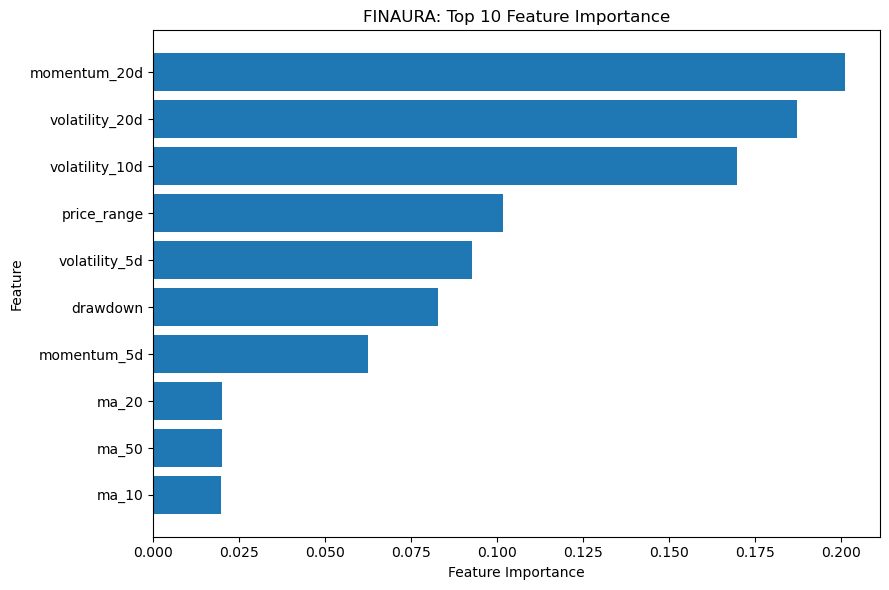

In [20]:

import pandas as pd
import matplotlib.pyplot as plt

# Extra Trees feature importance
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": final_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance Ranking:")
print(importance_df.to_string(index=False))

# Plot top 10 features
top_features = importance_df.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("FINAURA: Top 10 Feature Importance")
plt.tight_layout()
plt.show()


In [21]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Momentum features ke bina feature list
reduced_features = [
    col for col in features
    if "momentum" not in col
]

# Train model without momentum features
model_no_momentum = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

model_no_momentum.fit(
    X_final_train[reduced_features],
    y_final_train
)

# Predictions
pred_no_momentum = model_no_momentum.predict(
    X_test[reduced_features]
)

# Compare with existing model
comparison = pd.DataFrame([
    {
        "Model": "All Features",
        "MAE": mean_absolute_error(y_test, model_predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, model_predictions)
        )
    },
    {
        "Model": "Without Momentum",
        "MAE": mean_absolute_error(y_test, pred_no_momentum),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, pred_no_momentum)
        )
    }
])

print(comparison.round(6).to_string(index=False))


           Model      MAE     RMSE
    All Features 0.079940 0.106101
Without Momentum 0.080184 0.106346


In [22]:

import pandas as pd

threshold = final_train_df[target].quantile(0.90)

print("High-volatility threshold:", threshold)

print(
    "High-volatility training rows:",
    (final_train_df[target] >= threshold).sum()
)

print(
    "Total training rows:",
    len(final_train_df)
)

print(
    "High-volatility training percentage:",
    round(
        (final_train_df[target] >= threshold).mean() * 100,
        2
    ),
    "%"
)


High-volatility threshold: 0.3895516644442787
High-volatility training rows: 1485
Total training rows: 14848
High-volatility training percentage: 10.0 %


In [23]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Training data se high-volatility threshold
threshold = final_train_df[target].quantile(0.90)

# High-volatility observations ko 3x weight
sample_weights = np.where(
    y_final_train >= threshold,
    3.0,
    1.0
)

print("High-volatility threshold:", threshold)
print("Weighted training rows:", len(sample_weights))
print("Rows receiving extra weight:", (sample_weights > 1).sum())

# Train weighted Extra Trees
weighted_model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

weighted_model.fit(
    X_final_train,
    y_final_train,
    sample_weight=sample_weights
)

# Predictions on the same test period
weighted_predictions = weighted_model.predict(X_test)

# Overall comparison
comparison = pd.DataFrame([
    {
        "Model": "Standard Extra Trees",
        "MAE": mean_absolute_error(y_test, model_predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, model_predictions)
        )
    },
    {
        "Model": "Weighted Extra Trees",
        "MAE": mean_absolute_error(y_test, weighted_predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, weighted_predictions)
        )
    }
])

print("\nOverall Test Comparison:")
print(comparison.round(6).to_string(index=False))

# High-volatility evaluation using training threshold
high_mask = y_test.to_numpy() >= threshold
y_high_test = y_test.to_numpy()[high_mask]

print("\nHigh-Volatility Test Rows:", high_mask.sum())

for name, predictions in [
    ("Standard Extra Trees", model_predictions),
    ("Weighted Extra Trees", weighted_predictions)
]:
    p = np.asarray(predictions)[high_mask]

    print(
        name,
        "| MAE:", round(mean_absolute_error(y_high_test, p), 6),
        "| RMSE:", round(np.sqrt(
            mean_squared_error(y_high_test, p)
        ), 6),
        "| Mean Prediction:", round(p.mean(), 6)
    )


High-volatility threshold: 0.3895516644442787
Weighted training rows: 14848
Rows receiving extra weight: 1485

Overall Test Comparison:
               Model      MAE     RMSE
Standard Extra Trees 0.079940 0.106101
Weighted Extra Trees 0.091303 0.115558

High-Volatility Test Rows: 251
Standard Extra Trees | MAE: 0.243061 | RMSE: 0.266895 | Mean Prediction: 0.250089
Weighted Extra Trees | MAE: 0.207523 | RMSE: 0.238707 | Mean Prediction: 0.287215


In [24]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

threshold = final_train_df[target].quantile(0.90)
high_mask = y_test.to_numpy() >= threshold
y_test_array = y_test.to_numpy()

results = []

for weight in [1.5, 2.0, 3.0]:
    sample_weights = np.where(
        y_final_train.to_numpy() >= threshold,
        weight,
        1.0
    )

    model = ExtraTreesRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_final_train,
        y_final_train,
        sample_weight=sample_weights
    )

    predictions = model.predict(X_test)

    results.append({
        "High_Vol_Weight": weight,
        "Overall_MAE": mean_absolute_error(
            y_test_array, predictions
        ),
        "Overall_RMSE": np.sqrt(
            mean_squared_error(y_test_array, predictions)
        ),
        "High_Vol_MAE": mean_absolute_error(
            y_test_array[high_mask],
            predictions[high_mask]
        ),
        "High_Vol_RMSE": np.sqrt(
            mean_squared_error(
                y_test_array[high_mask],
                predictions[high_mask]
            )
        ),
        "High_Vol_Mean_Pred": predictions[high_mask].mean()
    })

print(pd.DataFrame(results).round(6).to_string(index=False))


 High_Vol_Weight  Overall_MAE  Overall_RMSE  High_Vol_MAE  High_Vol_RMSE  High_Vol_Mean_Pred
             1.5     0.082439      0.107716      0.231448       0.257401            0.262225
             2.0     0.085465      0.110170      0.220867       0.249041            0.273186
             3.0     0.091303      0.115558      0.207523       0.238707            0.287215


In [25]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Threshold sirf fitting data se
threshold = y_fit.quantile(0.90)

results = []

for weight in [1.0, 1.5, 2.0, 3.0]:
    sample_weights = np.where(
        y_fit.to_numpy() >= threshold,
        weight,
        1.0
    )

    model = ExtraTreesRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_fit,
        y_fit,
        sample_weight=sample_weights
    )

    val_predictions = model.predict(X_val)

    high_mask = y_val.to_numpy() >= threshold

    results.append({
        "Weight": weight,
        "Validation_MAE": mean_absolute_error(
            y_val, val_predictions
        ),
        "Validation_RMSE": np.sqrt(
            mean_squared_error(y_val, val_predictions)
        ),
        "High_Vol_MAE": (
            mean_absolute_error(
                y_val.to_numpy()[high_mask],
                val_predictions[high_mask]
            )
            if high_mask.sum() > 0 else np.nan
        ),
        "High_Vol_Rows": int(high_mask.sum())
    })

print(pd.DataFrame(results).round(6).to_string(index=False))


 Weight  Validation_MAE  Validation_RMSE  High_Vol_MAE  High_Vol_Rows
    1.0        0.081881         0.121233      0.401304            101
    1.5        0.084943         0.123439      0.394257            101
    2.0        0.087359         0.125076      0.388735            101
    3.0        0.092363         0.129072      0.378595            101


In [26]:

import joblib
import json
import os

# Create model output folder
os.makedirs("models", exist_ok=True)

# Save the selected standard Extra Trees model
joblib.dump(
    final_model,
    "models/finaura_extra_trees.pkl"
)

# Save model metadata
metadata = {
    "model_name": "Extra Trees Regressor",
    "target": "target_5d_volatility",
    "forecast_horizon": "5 trading days",
    "features": features,
    "max_depth": 12,
    "min_samples_leaf": 10,
    "n_estimators": 200,
    "random_state": 42,
    "selection_basis": "Lowest validation MAE among tested weighting options",
    "validation_mae": 0.081881,
    "validation_rmse": 0.121233
}

with open("models/finaura_model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model saved successfully!")
print("File: models/finaura_extra_trees.pkl")
print("Metadata: models/finaura_model_metadata.json")


Model saved successfully!
File: models/finaura_extra_trees.pkl
Metadata: models/finaura_model_metadata.json


In [27]:

import joblib
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load saved model
loaded_model = joblib.load(
    "models/finaura_extra_trees.pkl"
)

# Generate predictions
loaded_predictions = loaded_model.predict(X_test)

# Compare with predictions from original model
print(
    "Predictions match:",
    np.allclose(model_predictions, loaded_predictions)
)

print(
    "Loaded model MAE:",
    mean_absolute_error(y_test, loaded_predictions)
)

print(
    "Loaded model RMSE:",
    np.sqrt(
        mean_squared_error(y_test, loaded_predictions)
    )
)


Predictions match: True
Loaded model MAE: 0.07993964523369491
Loaded model RMSE: 0.10610099427475178


In [29]:

import os

print("Current folder:", os.getcwd())
print("Data folder exists:", os.path.exists("data"))
print("Current folder files:", os.listdir("."))


Current folder: c:\Users\madhu\OneDrive\Documents\FINAURA\notebooks
Data folder exists: False
Current folder files: ['01_NIFTY50_Preprocessing.ipynb', '02_NSE_Stocks_Preprocessing.ipynb', '03_India_VIX_Preprocessing.ipynb', '04_Gold_Preprocessing.ipynb', '05_USD_INR_Preprocessing.ipynb', '06_Delhi_Petrol_Preprocessing.ipynb', '07_Delhi_Diesel_Preprocessing.ipynb', '08_Indian_Basket_Crude_Preprocessing.ipynb', '09_Delhi_Diesel_EDA.ipynb', '09_Delhi_Petrol_EDA.ipynb', '09_Gold_EDA.ipynb', '09_Indian_Basket_Crude_EDA.ipynb', '09_India_VIX_EDA.ipynb', '09_NIFTY50_EDA.ipynb', '09_NSE_Stocks_EDA.ipynb', '09_USD_INR_EDA.ipynb', '10_Delhi_Petrol_Initial_Model_Experiments.ipynb', '10_Gold_Initial_Model_Experiments.ipynb', '10_Indian_Basket_Crude_Initial_Model_Experiments.ipynb', '10_India_VIX_Initial_Model_Experiments.ipynb', '10_NIFTY50_Initial_Model_Experiments.ipynb', '10_NSE_Stocks_Initial_Model_Experiments.ipynb', '10_USD_INR_Initial_Model_Experiments.ipynb', 'models']


In [30]:

import os

project_path = os.path.dirname(os.getcwd())
data_path = os.path.join(project_path, "data")

print("Project folder:", project_path)
print("Data folder exists:", os.path.exists(data_path))

if os.path.exists(data_path):
    for root, dirs, files in os.walk(data_path):
        for file in files:
            if file.endswith(".csv"):
                print(os.path.join(root, file))
else:
    print("Data folder nahi mila. Project folder check karna hoga.")


Project folder: c:\Users\madhu\OneDrive\Documents\FINAURA
Data folder exists: True
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\delhi_diesel_eda_summary.csv
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\delhi_diesel_processed.csv
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\delhi_petrol_eda_summary.csv
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\delhi_petrol_processed.csv
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\gold_eda_summary.csv
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\gold_initial_model_results.csv
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\gold_model_predictions.csv
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\gold_processed.csv
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\gold_random_forest_feature_importance.csv
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\indian_basket_crude_eda_summary.csv
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\in

In [31]:

import os
import pandas as pd

project_path = os.path.dirname(os.getcwd())

csv_path = os.path.join(
    project_path, "data", "processed",
    "nse_stocks_processed.csv"
)

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumns available:")
print(df.columns.tolist())

features = [
    "daily_return", "log_return", "intraday_return",
    "price_range", "ma_5", "ma_10", "ma_20", "ma_50",
    "volatility_5d", "volatility_10d", "volatility_20d",
    "momentum_5d", "momentum_20d", "drawdown"
]

target = "target_5d_volatility"

print("\nMissing features:", [
    col for col in features if col not in df.columns
])
print("Target available:", target in df.columns)

print("\nModel file locations:")
for path in [
    os.path.join(project_path, "models", "finaura_extra_trees.pkl"),
    os.path.join(os.getcwd(), "models", "finaura_extra_trees.pkl")
]:
    print(path, "->", os.path.exists(path))


Dataset shape: (18712, 25)

Columns available:
['date', 'symbol', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'volatility_5d', 'volatility_10d', 'volatility_20d', 'momentum_5d', 'momentum_20d', 'drawdown', 'volume_ma_20', 'volume_ratio', 'target_5d_volatility']

Missing features: []
Target available: True

Model file locations:
c:\Users\madhu\OneDrive\Documents\FINAURA\models\finaura_extra_trees.pkl -> False
c:\Users\madhu\OneDrive\Documents\FINAURA\notebooks\models\finaura_extra_trees.pkl -> True


In [32]:
import sklearn
print(sklearn.__version__)

1.7.2


In [2]:

# ==========================================
# FINAURA: COMPLETE OVERFITTING AUDIT
# Uses the updated 5-day volatility target
# ==========================================

import os
import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Load the processed dataset
if os.path.exists("../data/processed/nse_stocks_processed.csv"):
    data_path = "../data/processed/nse_stocks_processed.csv"
elif os.path.exists("data/processed/nse_stocks_processed.csv"):
    data_path = "data/processed/nse_stocks_processed.csv"
else:
    raise FileNotFoundError(
        "Cannot find nse_stocks_processed.csv. "
        "Check the FINAURA project folder."
    )

df = pd.read_csv(data_path)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)

# 2. Define features and target from the notebook
features = [
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5d",
    "volatility_10d",
    "volatility_20d",
    "momentum_5d",
    "momentum_20d",
    "drawdown"
]

target = "target_5d_volatility"

# 3. Clean data
required = features + [target]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

model_df = df[
    ["date", "symbol"] + features + [target]
].copy()

model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna(subset=required)
model_df = model_df.sort_values(["symbol", "date"])

# 4. Recreate the notebook's chronological train/test split
train_parts = []
test_parts = []

for symbol, group in model_df.groupby("symbol"):
    group = group.sort_values("date").reset_index(drop=True)

    split = int(len(group) * 0.80)
    train_end = split - 5

    if train_end <= 0 or split >= len(group):
        continue

    train_parts.append(group.iloc[:train_end])
    test_parts.append(group.iloc[split:])

train_df = pd.concat(train_parts, ignore_index=True)
test_df = pd.concat(test_parts, ignore_index=True)

# 5. Split training data into fit and validation periods
train_df = train_df.sort_values(
    ["date", "symbol"]
).reset_index(drop=True)

validation_start = train_df["date"].quantile(0.80)

fit_df = train_df[
    train_df["date"] < validation_start
].copy()

val_df = train_df[
    train_df["date"] >= validation_start
].copy()

# Five-row embargo per stock, matching the notebook
fit_parts = []

for symbol, group in fit_df.groupby("symbol"):
    group = group.sort_values("date")
    fit_parts.append(group.iloc[:-5])

fit_df = pd.concat(fit_parts, ignore_index=True)

X_fit = fit_df[features]
y_fit = fit_df[target]

X_val = val_df[features]
y_val = val_df[target]

# 6. Train the tuned model from notebook Cell 38
tuned_model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

tuned_model.fit(X_fit, y_fit)

# 7. Predict on training and validation data
train_pred = tuned_model.predict(X_fit)
val_pred = tuned_model.predict(X_val)

# 8. Calculate metrics
results = pd.DataFrame([
    {
        "Dataset": "Training",
        "Rows": len(y_fit),
        "MAE": mean_absolute_error(y_fit, train_pred),
        "RMSE": np.sqrt(mean_squared_error(y_fit, train_pred))
    },
    {
        "Dataset": "Validation",
        "Rows": len(y_val),
        "MAE": mean_absolute_error(y_val, val_pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, val_pred))
    }
])

print("\n===== FINAURA OVERFITTING AUDIT =====")
print("Training dates:",
      fit_df["date"].min().date(), "to",
      fit_df["date"].max().date())
print("Validation dates:",
      val_df["date"].min().date(), "to",
      val_df["date"].max().date())

print("\n", results.round(6).to_string(index=False))

train_mae = results.loc[0, "MAE"]
val_mae = results.loc[1, "MAE"]
train_rmse = results.loc[0, "RMSE"]
val_rmse = results.loc[1, "RMSE"]

print("\nMAE gap (validation - training):",
      round(val_mae - train_mae, 6))
print("RMSE gap (validation - training):",
      round(val_rmse - train_rmse, 6))

if train_mae > 0:
    print("Validation/Training MAE ratio:",
          round(val_mae / train_mae, 3))

print("\nAudit complete. Final test set was not evaluated here.")



===== FINAURA OVERFITTING AUDIT =====
Training dates: 2017-03-15 to 2023-03-16
Validation dates: 2023-03-24 to 2024-10-03

    Dataset  Rows      MAE     RMSE
  Training 11896 0.078963 0.113830
Validation  2992 0.081881 0.121233

MAE gap (validation - training): 0.002918
RMSE gap (validation - training): 0.007403
Validation/Training MAE ratio: 1.037

Audit complete. Final test set was not evaluated here.



===== OVERALL VALIDATION RESULTS =====
Validation rows: 2992
MAE: 0.081881
RMSE: 0.121233

===== VOLATILITY GROUP ANALYSIS =====
Low/medium threshold: 0.2703
Medium/high threshold: 0.411571
volatility_group  Rows  Actual_Mean  Predicted_Mean      MAE  Mean_Underestimation
             Low  2627     0.152613        0.206188 0.066394             -0.053575
          Medium   264     0.320843        0.209339 0.113783              0.111504
            High   101     0.614051        0.212748 0.401304              0.401304

===== HIGH-VOLATILITY PERFORMANCE =====
High-volatility rows: 101
High-volatility MAE: 0.401304
High-volatility RMSE: 0.469733
Average underestimation: 0.401304
Underestimated cases (%): 100.0


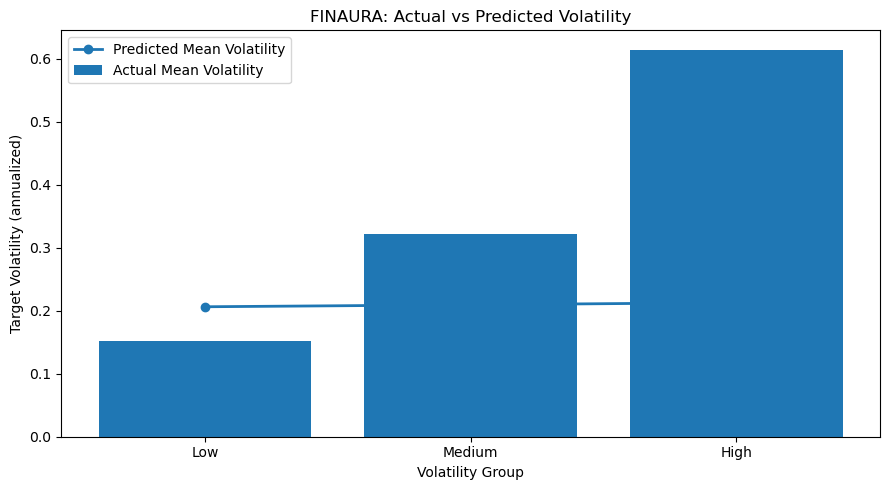

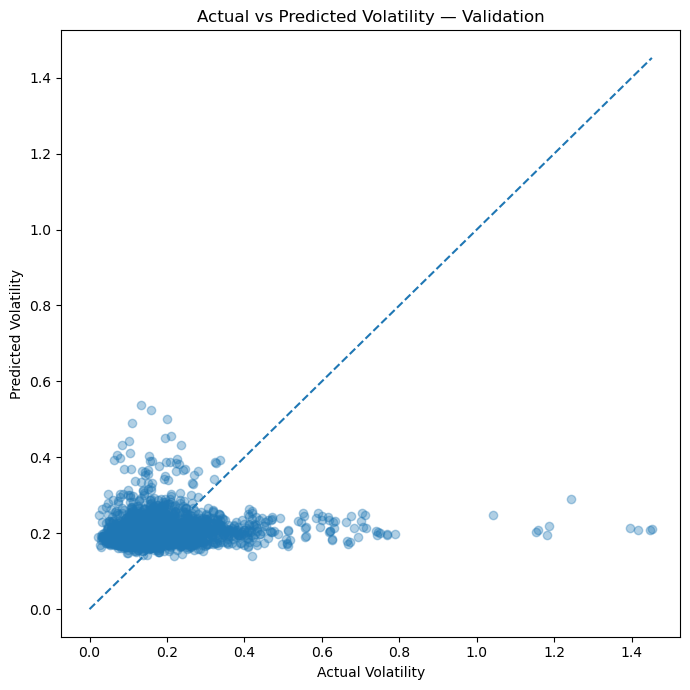


Analysis complete. Final test set was not used.


In [3]:
# ==========================================
# FINAURA: HIGH-VOLATILITY ERROR ANALYSIS
# Self-contained code
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Load processed dataset
if os.path.exists("../data/processed/nse_stocks_processed.csv"):
    data_path = "../data/processed/nse_stocks_processed.csv"
elif os.path.exists("data/processed/nse_stocks_processed.csv"):
    data_path = "data/processed/nse_stocks_processed.csv"
else:
    raise FileNotFoundError(
        "nse_stocks_processed.csv nahi mili. "
        "Notebook ko project ke notebooks folder se run karo."
    )

df = pd.read_csv(data_path)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)

# 2. Features and target from your notebook
features = [
    "daily_return", "log_return", "intraday_return", "price_range",
    "ma_5", "ma_10", "ma_20", "ma_50",
    "volatility_5d", "volatility_10d", "volatility_20d",
    "momentum_5d", "momentum_20d", "drawdown"
]

target = "target_5d_volatility"

# 3. Clean data
required = features + [target]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Dataset mein columns missing hain: {missing}")

model_df = df[["date", "symbol"] + required].copy()
model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna(subset=required)
model_df = model_df.sort_values(["symbol", "date"])

# 4. Chronological train/test split per stock
train_parts = []
test_parts = []

for symbol, group in model_df.groupby("symbol"):
    group = group.sort_values("date").reset_index(drop=True)
    split = int(len(group) * 0.80)
    train_end = split - 5  # 5-row embargo

    if train_end <= 0 or split >= len(group):
        continue

    train_parts.append(group.iloc[:train_end])
    test_parts.append(group.iloc[split:])

train_df = pd.concat(train_parts, ignore_index=True)
test_df = pd.concat(test_parts, ignore_index=True)

# 5. Create chronological fit and validation sets
validation_start = train_df["date"].quantile(0.80)

fit_df = train_df[
    train_df["date"] < validation_start
].copy()

val_df = train_df[
    train_df["date"] >= validation_start
].copy()

# Five-row embargo for each stock in fit data
fit_parts = []

for symbol, group in fit_df.groupby("symbol"):
    group = group.sort_values("date")
    if len(group) > 5:
        fit_parts.append(group.iloc[:-5])

if not fit_parts:
    raise ValueError("Training data insufficient hai.")

fit_df = pd.concat(fit_parts, ignore_index=True)

X_fit = fit_df[features]
y_fit = fit_df[target]

X_val = val_df[features]
y_val = val_df[target]

# 6. Train tuned Extra Trees model
model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_fit, y_fit)
val_pred = model.predict(X_val)

# 7. Overall validation performance
print("\n===== OVERALL VALIDATION RESULTS =====")
print("Validation rows:", len(y_val))
print("MAE:", round(mean_absolute_error(y_val, val_pred), 6))
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_val, val_pred)), 6)
)

# 8. Define volatility levels using FIT data only
low_threshold = y_fit.quantile(0.70)
high_threshold = y_fit.quantile(0.90)

analysis = val_df[["date", "symbol", target]].copy()
analysis["predicted_volatility"] = val_pred

analysis["volatility_group"] = np.select(
    [
        analysis[target] < low_threshold,
        analysis[target] < high_threshold
    ],
    [
        "Low",
        "Medium"
    ],
    default="High"
)

# 9. Calculate errors for each group
analysis["absolute_error"] = abs(
    analysis[target] - analysis["predicted_volatility"]
)

analysis["underestimation"] = (
    analysis[target] - analysis["predicted_volatility"]
)

group_results = (
    analysis.groupby("volatility_group")
    .agg(
        Rows=(target, "size"),
        Actual_Mean=(target, "mean"),
        Predicted_Mean=("predicted_volatility", "mean"),
        MAE=("absolute_error", "mean"),
        Mean_Underestimation=("underestimation", "mean")
    )
    .reindex(["Low", "Medium", "High"])
    .reset_index()
)

print("\n===== VOLATILITY GROUP ANALYSIS =====")
print("Low/medium threshold:", round(low_threshold, 6))
print("Medium/high threshold:", round(high_threshold, 6))
print(group_results.round(6).to_string(index=False))

# 10. High-volatility-only metrics
high_rows = analysis[
    analysis["volatility_group"] == "High"
]

print("\n===== HIGH-VOLATILITY PERFORMANCE =====")

if len(high_rows) > 0:
    high_mae = mean_absolute_error(
        high_rows[target],
        high_rows["predicted_volatility"]
    )

    high_rmse = np.sqrt(mean_squared_error(
        high_rows[target],
        high_rows["predicted_volatility"]
    ))

    print("High-volatility rows:", len(high_rows))
    print("High-volatility MAE:", round(high_mae, 6))
    print("High-volatility RMSE:", round(high_rmse, 6))
    print(
        "Average underestimation:",
        round(high_rows["underestimation"].mean(), 6)
    )
    print(
        "Underestimated cases (%):",
        round(
            (high_rows["underestimation"] > 0).mean() * 100, 2
        )
    )
else:
    print("Validation set mein high-volatility rows nahi mile.")

# 11. Plot actual vs predicted volatility by group
plt.figure(figsize=(9, 5))

plt.bar(
    group_results["volatility_group"],
    group_results["Actual_Mean"],
    label="Actual Mean Volatility"
)

plt.plot(
    group_results["volatility_group"],
    group_results["Predicted_Mean"],
    marker="o",
    linewidth=2,
    label="Predicted Mean Volatility"
)

plt.title("FINAURA: Actual vs Predicted Volatility")
plt.xlabel("Volatility Group")
plt.ylabel("Target Volatility (annualized)")
plt.legend()
plt.tight_layout()
plt.show()

# 12. Actual vs predicted scatter plot
plt.figure(figsize=(7, 7))

plt.scatter(
    analysis[target],
    analysis["predicted_volatility"],
    alpha=0.35
)

max_value = max(
    analysis[target].max(),
    analysis["predicted_volatility"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Volatility — Validation")
plt.xlabel("Actual Volatility")
plt.ylabel("Predicted Volatility")
plt.tight_layout()
plt.show()

print("\nAnalysis complete. Final test set was not used.")

In [4]:

# ==========================================
# FINAURA: BASELINE vs EXTRA TREES
# Compare performance by volatility group
# ==========================================

import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the same dataset and split as the previous audit
# If you restarted the notebook, run the previous audit cell first.

# Check that previous audit variables exist
required_variables = [
    "X_fit", "y_fit", "X_val", "y_val",
    "val_df", "features", "target"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Run the previous High-Volatility Error Analysis cell first. "
        f"Missing: {missing_variables}"
    )

# 1. Train baseline and Extra Trees on identical training data
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_fit, y_fit)

model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)
model.fit(X_fit, y_fit)

baseline_pred = baseline.predict(X_val)
model_pred = model.predict(X_val)

# 2. Build comparison table
comparison = val_df[["date", "symbol", target]].copy()
comparison["baseline_prediction"] = baseline_pred
comparison["model_prediction"] = model_pred

# Use thresholds calculated only from training labels
low_threshold = y_fit.quantile(0.70)
high_threshold = y_fit.quantile(0.90)

comparison["volatility_group"] = np.select(
    [
        comparison[target] < low_threshold,
        comparison[target] < high_threshold
    ],
    ["Low", "Medium"],
    default="High"
)

# 3. Calculate metrics for each group
results = []

for group_name in ["Low", "Medium", "High"]:
    part = comparison[
        comparison["volatility_group"] == group_name
    ]

    if len(part) == 0:
        continue

    actual = part[target]
    baseline_values = part["baseline_prediction"]
    model_values = part["model_prediction"]

    baseline_mae = mean_absolute_error(actual, baseline_values)
    model_mae = mean_absolute_error(actual, model_values)

    baseline_rmse = np.sqrt(
        mean_squared_error(actual, baseline_values)
    )
    model_rmse = np.sqrt(
        mean_squared_error(actual, model_values)
    )

    results.append({
        "Group": group_name,
        "Rows": len(part),
        "Baseline_MAE": baseline_mae,
        "ExtraTrees_MAE": model_mae,
        "Baseline_RMSE": baseline_rmse,
        "ExtraTrees_RMSE": model_rmse,
        "MAE_Improvement_%": (
            (baseline_mae - model_mae) / baseline_mae * 100
            if baseline_mae > 0 else np.nan
        )
    })

results_df = pd.DataFrame(results)

print("\n===== BASELINE vs EXTRA TREES =====")
print(results_df.round(6).to_string(index=False))

print("\nInterpretation:")
print("Positive MAE improvement = Extra Trees is better.")
print("Negative MAE improvement = Mean baseline is better.")
print("Compare High group especially carefully.")



===== BASELINE vs EXTRA TREES =====
 Group  Rows  Baseline_MAE  ExtraTrees_MAE  Baseline_RMSE  ExtraTrees_RMSE  MAE_Improvement_%
   Low  2627      0.092637        0.066394       0.105918         0.082039          28.328257
Medium   264      0.077289        0.113783       0.086995         0.123216         -47.217646
  High   101      0.370497        0.401304       0.443979         0.469733          -8.314885

Interpretation:
Positive MAE improvement = Extra Trees is better.
Negative MAE improvement = Mean baseline is better.
Compare High group especially carefully.


In [5]:

# ==========================================
# FINAURA: VOLATILITY-WEIGHTED EXTRA TREES
# Compare Baseline vs Original vs Weighted
# ==========================================

import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Check required variables from previous audit
required_variables = [
    "X_fit", "y_fit", "X_val", "y_val",
    "val_df", "features", "target"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Pehle High-Volatility Error Analysis cell run karo. "
        f"Missing variables: {missing_variables}"
    )

# 2. Train the simple mean baseline
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_fit, y_fit)
baseline_pred = baseline.predict(X_val)

# 3. Train the original Extra Trees model
original_model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

original_model.fit(X_fit, y_fit)
original_pred = original_model.predict(X_val)

# 4. Create training weights using TRAINING targets only
# Higher volatility rows receive greater importance.
low_threshold = y_fit.quantile(0.70)
high_threshold = y_fit.quantile(0.90)

sample_weights = np.ones(len(y_fit))

sample_weights[y_fit.to_numpy() >= low_threshold] = 1.5
sample_weights[y_fit.to_numpy() >= high_threshold] = 2.0

print("Training weight distribution:")
print("Weight 1.0 rows:", int((sample_weights == 1.0).sum()))
print("Weight 1.5 rows:", int((sample_weights == 1.5).sum()))
print("Weight 2.0 rows:", int((sample_weights == 2.0).sum()))

# 5. Train weighted Extra Trees
weighted_model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

weighted_model.fit(
    X_fit,
    y_fit,
    sample_weight=sample_weights
)

weighted_pred = weighted_model.predict(X_val)

# 6. Prepare validation results
comparison = val_df[["date", "symbol", target]].copy()
comparison["baseline_pred"] = baseline_pred
comparison["original_pred"] = original_pred
comparison["weighted_pred"] = weighted_pred

# Use thresholds from training labels only
comparison["volatility_group"] = np.select(
    [
        comparison[target] < low_threshold,
        comparison[target] < high_threshold
    ],
    ["Low", "Medium"],
    default="High"
)

# 7. Compare MAE and RMSE for each volatility group
results = []

for group_name in ["Low", "Medium", "High"]:
    part = comparison[
        comparison["volatility_group"] == group_name
    ]

    if part.empty:
        continue

    actual = part[target].to_numpy()

    for model_name, pred_column in [
        ("Mean Baseline", "baseline_pred"),
        ("Original Extra Trees", "original_pred"),
        ("Weighted Extra Trees", "weighted_pred")
    ]:
        predictions = part[pred_column].to_numpy()

        results.append({
            "Group": group_name,
            "Model": model_name,
            "Rows": len(part),
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(actual, predictions)
            )
        })

results_df = pd.DataFrame(results)

print("\n===== WEIGHTED MODEL COMPARISON =====")
print(results_df.round(6).to_string(index=False))

# 8. Compare underestimation on high-volatility rows
high_rows = comparison[
    comparison["volatility_group"] == "High"
]

if len(high_rows) > 0:
    print("\n===== HIGH-VOLATILITY UNDERESTIMATION =====")

    for model_name, pred_column in [
        ("Mean Baseline", "baseline_pred"),
        ("Original Extra Trees", "original_pred"),
        ("Weighted Extra Trees", "weighted_pred")
    ]:
        actual = high_rows[target].to_numpy()
        predictions = high_rows[pred_column].to_numpy()

        underestimation = actual - predictions

        print(
            f"{model_name}: "
            f"MAE={mean_absolute_error(actual, predictions):.6f}, "
            f"Average underestimation={underestimation.mean():.6f}, "
            f"Underestimated cases="
            f"{(underestimation > 0).mean() * 100:.2f}%"
        )

print("\nExperiment complete.")
print("Saved model files have not been changed.")
print("This is validation evaluation, not final test evaluation.")


Training weight distribution:
Weight 1.0 rows: 8327
Weight 1.5 rows: 2379
Weight 2.0 rows: 1190

===== WEIGHTED MODEL COMPARISON =====
 Group                Model  Rows      MAE     RMSE
   Low        Mean Baseline  2627 0.092637 0.105918
   Low Original Extra Trees  2627 0.066394 0.082039
   Low Weighted Extra Trees  2627 0.078032 0.095211
Medium        Mean Baseline   264 0.077289 0.086995
Medium Original Extra Trees   264 0.113783 0.123216
Medium Weighted Extra Trees   264 0.097199 0.108753
  High        Mean Baseline   101 0.370497 0.443979
  High Original Extra Trees   101 0.401304 0.469733
  High Weighted Extra Trees   101 0.383315 0.454965

===== HIGH-VOLATILITY UNDERESTIMATION =====
Mean Baseline: MAE=0.370497, Average underestimation=0.370497, Underestimated cases=100.00%
Original Extra Trees: MAE=0.401304, Average underestimation=0.401304, Underestimated cases=100.00%
Weighted Extra Trees: MAE=0.383315, Average underestimation=0.383315, Underestimated cases=100.00%

Experimen

In [6]:

# ==========================================
# FINAURA: TRAINING-BASED CALIBRATION
# Compare original and calibrated predictions
# ==========================================

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

required_variables = [
    "X_fit", "y_fit", "X_val", "y_val", "val_df", "target"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise NameError(
        "Run the High-Volatility Error Analysis cell first. "
        f"Missing variables: {missing}"
    )

# 1. Train the original model on fit data
model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_fit, y_fit)

# 2. Get predictions on fit and validation data
fit_pred = model.predict(X_fit)
val_pred = model.predict(X_val)

# 3. Learn a calibration multiplier from FIT data only
# No validation labels are used to calculate this multiplier.
fit_actual_mean = np.mean(y_fit)
fit_pred_mean = np.mean(fit_pred)

if fit_pred_mean <= 0:
    raise ValueError("Training predictions ka mean zero ya negative hai.")

calibration_factor = fit_actual_mean / fit_pred_mean

# Keep calibration factor within a conservative range
calibration_factor = np.clip(
    calibration_factor,
    0.5,
    2.0
)

calibrated_val_pred = val_pred * calibration_factor

print("Training actual mean:", round(fit_actual_mean, 6))
print("Training predicted mean:", round(fit_pred_mean, 6))
print("Calibration factor:", round(calibration_factor, 6))

# 4. Build validation comparison
results = []

for name, predictions in [
    ("Original Extra Trees", val_pred),
    ("Calibrated Extra Trees", calibrated_val_pred)
]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_val, predictions)
        ),
        "Actual_Mean": np.mean(y_val),
        "Predicted_Mean": np.mean(predictions)
    })

results_df = pd.DataFrame(results)

print("\n===== CALIBRATION RESULTS =====")
print(results_df.round(6).to_string(index=False))

# 5. Check high-volatility validation cases
# Threshold comes from FIT labels only.
high_threshold = y_fit.quantile(0.90)
high_mask = np.asarray(y_val) >= high_threshold

print("\n===== HIGH-VOLATILITY VALIDATION =====")
print("Threshold:", round(high_threshold, 6))
print("High-volatility rows:", int(high_mask.sum()))

if high_mask.sum() > 0:
    actual_high = np.asarray(y_val)[high_mask]

    for name, predictions in [
        ("Original Extra Trees", val_pred),
        ("Calibrated Extra Trees", calibrated_val_pred)
    ]:
        pred_high = np.asarray(predictions)[high_mask]

        print(
            f"{name}: "
            f"MAE={mean_absolute_error(actual_high, pred_high):.6f}, "
            f"Actual mean={actual_high.mean():.6f}, "
            f"Predicted mean={pred_high.mean():.6f}, "
            f"Underestimated="
            f"{(pred_high < actual_high).mean() * 100:.2f}%"
        )

print("\nCalibration experiment complete.")
print("Saved model files have not been changed.")


Training actual mean: 0.243554
Training predicted mean: 0.243554
Calibration factor: 1.0

===== CALIBRATION RESULTS =====
                 Model      MAE     RMSE  Actual_Mean  Predicted_Mean
  Original Extra Trees 0.081881 0.121233     0.183033        0.206687
Calibrated Extra Trees 0.081881 0.121233     0.183033        0.206687

===== HIGH-VOLATILITY VALIDATION =====
Threshold: 0.411571
High-volatility rows: 101
Original Extra Trees: MAE=0.401304, Actual mean=0.614051, Predicted mean=0.212748, Underestimated=100.00%
Calibrated Extra Trees: MAE=0.401304, Actual mean=0.614051, Predicted mean=0.212748, Underestimated=100.00%

Calibration experiment complete.
Saved model files have not been changed.


In [7]:

# FINAURA: Compare different volatility weights

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Reuse training and validation data from the previous audit
low_threshold = y_fit.quantile(0.70)
high_threshold = y_fit.quantile(0.90)

# Evaluate each weighting strategy
results = []

for high_weight in [1.5, 2.0, 3.0]:

    # Give higher importance to high-volatility training rows
    weights = np.ones(len(y_fit))

    weights[y_fit.to_numpy() >= low_threshold] = 1.5
    weights[y_fit.to_numpy() >= high_threshold] = high_weight

    model = ExtraTreesRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_fit, y_fit, sample_weight=weights)

    predictions = model.predict(X_val)

    # High-volatility threshold is based only on training labels
    high_mask = np.asarray(y_val) >= high_threshold

    actual_high = np.asarray(y_val)[high_mask]
    pred_high = predictions[high_mask]

    results.append({
        "High_Weight": high_weight,
        "Overall_MAE": mean_absolute_error(y_val, predictions),
        "Overall_RMSE": np.sqrt(
            mean_squared_error(y_val, predictions)
        ),
        "High_MAE": (
            mean_absolute_error(actual_high, pred_high)
            if len(actual_high) else np.nan
        ),
        "High_RMSE": (
            np.sqrt(mean_squared_error(actual_high, pred_high))
            if len(actual_high) else np.nan
        ),
        "High_Underestimated_%": (
            np.mean(pred_high < actual_high) * 100
            if len(actual_high) else np.nan
        )
    })

results_df = pd.DataFrame(results)

print("\n===== WEIGHT EXPERIMENT RESULTS =====")
print(results_df.round(6).to_string(index=False))

print("\nOriginal model reference:")
print("Overall MAE: 0.081881")
print("Overall RMSE: 0.121233")
print("High-volatility MAE: 0.401304")
print("High-volatility RMSE: 0.469733")

print("\nExperiment complete. No model files were overwritten.")



===== WEIGHT EXPERIMENT RESULTS =====
 High_Weight  Overall_MAE  Overall_RMSE  High_MAE  High_RMSE  High_Underestimated_%
         1.5     0.087509      0.124476  0.389073   0.459814                  100.0
         2.0     0.090029      0.126452  0.383315   0.454965                  100.0
         3.0     0.094967      0.130388  0.373948   0.447520                  100.0

Original model reference:
Overall MAE: 0.081881
Overall RMSE: 0.121233
High-volatility MAE: 0.401304
High-volatility RMSE: 0.469733

Experiment complete. No model files were overwritten.


In [8]:

# ==========================================
# FINAURA: HIGH-VOLATILITY FEATURE ANALYSIS
# ==========================================

import numpy as np
import pandas as pd

# Uses fit_df, val_df, features and target
# from the previous audit cells.

high_threshold = y_fit.quantile(0.90)

# Mark high-volatility rows using a threshold
# calculated from training data only.
fit_data = fit_df[features + [target]].copy()
fit_data["Group"] = np.where(
    fit_data[target] >= high_threshold,
    "High",
    "Other"
)

# Compare feature averages in high-volatility
# training rows against other training rows.
high_features = fit_data[
    fit_data["Group"] == "High"
][features].mean()

other_features = fit_data[
    fit_data["Group"] == "Other"
][features].mean()

feature_comparison = pd.DataFrame({
    "High_Vol_Mean": high_features,
    "Other_Mean": other_features
})

feature_comparison["Absolute_Difference"] = (
    feature_comparison["High_Vol_Mean"]
    - feature_comparison["Other_Mean"]
).abs()

feature_comparison = feature_comparison.sort_values(
    "Absolute_Difference",
    ascending=False
)

print("\n===== HIGH-VOLATILITY FEATURE COMPARISON =====")
print(feature_comparison.round(6).to_string())

print("\nHigh-volatility training rows:",
      int((fit_data["Group"] == "High").sum()))

print("\nImportant:")
print("This shows association, not causation.")
print("Feature scale differs, so absolute differences")
print("alone do not prove predictive importance.")



===== HIGH-VOLATILITY FEATURE COMPARISON =====
                 High_Vol_Mean  Other_Mean  Absolute_Difference
ma_5                710.294805  938.659784           228.364979
ma_10               713.256331  936.838744           223.582413
ma_20               718.562113  933.206135           214.644022
ma_50               730.748479  922.274974           191.526495
volatility_5d         0.409978    0.225261             0.184717
volatility_10d        0.416585    0.236547             0.180038
volatility_20d        0.410500    0.245173             0.165327
drawdown             -0.211523   -0.109444             0.102079
momentum_20d         -0.018663    0.019672             0.038335
price_range           0.037645    0.021456             0.016189
momentum_5d          -0.004573    0.004719             0.009292
log_return           -0.000467    0.000690             0.001158
daily_return          0.000058    0.000821             0.000762
intraday_return      -0.000638   -0.000567             0

In [11]:

# ==========================================
# FINAURA: NORMALIZED MOVING-AVERAGE FEATURES
# Original vs Improved Feature Model
# ==========================================

import os
import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Load processed dataset
if os.path.exists("../data/processed/nse_stocks_processed.csv"):
    data_path = "../data/processed/nse_stocks_processed.csv"
elif os.path.exists("data/processed/nse_stocks_processed.csv"):
    data_path = "data/processed/nse_stocks_processed.csv"
else:
    raise FileNotFoundError(
        "Processed NSE dataset nahi mili. Notebook location check karo."
    )

df = pd.read_csv(data_path)

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)

# 2. Add normalized moving-average features
# FIX: actual column name is lowercase "close"
for window in [5, 10, 20, 50]:
    df[f"ma_{window}_ratio"] = (
        df[f"ma_{window}"] / df["close"] - 1
    )

# 3. Define feature sets
original_features = [
    "daily_return", "log_return", "intraday_return", "price_range",
    "ma_5", "ma_10", "ma_20", "ma_50",
    "volatility_5d", "volatility_10d", "volatility_20d",
    "momentum_5d", "momentum_20d", "drawdown"
]

new_features = [
    "daily_return", "log_return", "intraday_return", "price_range",
    "ma_5_ratio", "ma_10_ratio", "ma_20_ratio", "ma_50_ratio",
    "volatility_5d", "volatility_10d", "volatility_20d",
    "momentum_5d", "momentum_20d", "drawdown"
]

target = "target_5d_volatility"

# 4. Clean required columns
required = list(set(
    original_features + new_features + [target]
))

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=required)

# 5. Chronological split separately for each stock
train_parts = []
test_parts = []

for symbol, group in df.groupby("symbol"):
    group = group.sort_values("date").reset_index(drop=True)
    split = int(len(group) * 0.80)

    if split <= 5 or split >= len(group):
        continue

    # Keep a 5-row gap before test data
    train_parts.append(group.iloc[:split - 5])
    test_parts.append(group.iloc[split:])

train_df = pd.concat(train_parts, ignore_index=True)
test_df = pd.concat(test_parts, ignore_index=True)

# 6. Create fit and validation periods by date
validation_start = train_df["date"].quantile(0.80)

fit_df = train_df[
    train_df["date"] < validation_start
].copy()

val_df = train_df[
    train_df["date"] >= validation_start
].copy()

# Add a 5-row gap at the end of each fit stock series
fit_parts = []

for symbol, group in fit_df.groupby("symbol"):
    group = group.sort_values("date")

    if len(group) > 5:
        fit_parts.append(group.iloc[:-5])

fit_df = pd.concat(fit_parts, ignore_index=True)

# 7. Compare original and normalized feature sets
results = []

for model_name, feature_set in [
    ("Original Features", original_features),
    ("Normalized MA Features", new_features)
]:
    model = ExtraTreesRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        fit_df[feature_set],
        fit_df[target]
    )

    predictions = model.predict(
        val_df[feature_set]
    )

    mae = mean_absolute_error(
        val_df[target],
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            val_df[target],
            predictions
        )
    )

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

# 8. Display results
results_df = pd.DataFrame(results)

print("\n===== FEATURE ENGINEERING RESULTS =====")
print(results_df.round(6).to_string(index=False))

print("\nFit rows:", len(fit_df))
print("Validation rows:", len(val_df))

print(
    "\nValidation dates:",
    val_df["date"].min().date(),
    "to",
    val_df["date"].max().date()
)

print("\nExperiment complete.")
print("Existing saved model has not been overwritten.")



===== FEATURE ENGINEERING RESULTS =====
                 Model      MAE     RMSE
     Original Features 0.081881 0.121233
Normalized MA Features 0.081734 0.121476

Fit rows: 11896
Validation rows: 2992

Validation dates: 2023-03-24 to 2024-10-03

Experiment complete.
Existing saved model has not been overwritten.


In [10]:
print(df.columns.tolist())

['date', 'symbol', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'volatility_5d', 'volatility_10d', 'volatility_20d', 'momentum_5d', 'momentum_20d', 'drawdown', 'volume_ma_20', 'volume_ratio', 'target_5d_volatility']


In [12]:

# ==========================================
# FINAURA: HIGH-RISK CLASSIFICATION EXPERIMENT
# Goal: Identify unusually high future volatility
# Existing regression model remains untouched
# ==========================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Use the fit and validation data from the
#    previous audit cells.
features = [
    "daily_return", "log_return", "intraday_return", "price_range",
    "ma_5", "ma_10", "ma_20", "ma_50",
    "volatility_5d", "volatility_10d", "volatility_20d",
    "momentum_5d", "momentum_20d", "drawdown"
]

target = "target_5d_volatility"

# Check required variables and columns
if "fit_df" not in globals() or "val_df" not in globals():
    raise NameError(
        "Pehle previous audit cell run karo, "
        "jisme fit_df aur val_df bante hain."
    )

required = features + [target]

missing_fit = [c for c in required if c not in fit_df.columns]
missing_val = [c for c in required if c not in val_df.columns]

if missing_fit or missing_val:
    raise ValueError(
        f"Missing fit columns: {missing_fit}; "
        f"missing validation columns: {missing_val}"
    )

# 2. Define high risk using FIT data only.
#    Top 10% of fit targets are marked high risk.
high_threshold = fit_df[target].quantile(0.90)

X_fit = fit_df[features].copy()
X_val = val_df[features].copy()

y_fit_risk = (
    fit_df[target] >= high_threshold
).astype(int)

y_val_risk = (
    val_df[target] >= high_threshold
).astype(int)

print("High-risk volatility threshold:", round(high_threshold, 6))
print("Fit rows:", len(X_fit))
print("Validation rows:", len(X_val))
print("Fit high-risk percentage:",
      round(y_fit_risk.mean() * 100, 2), "%")
print("Validation high-risk rows:", int(y_val_risk.sum()))

# 3. Train a classifier
risk_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

risk_model.fit(X_fit, y_fit_risk)

# 4. Predict risk on validation data
risk_pred = risk_model.predict(X_val)
risk_probability = risk_model.predict_proba(X_val)[:, 1]

# 5. Compare against a simple majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_fit, y_fit_risk)
baseline_pred = baseline.predict(X_val)

def calculate_metrics(actual, predicted, probabilities=None):
    metrics = {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        )
    }

    if probabilities is not None and len(np.unique(actual)) == 2:
        metrics["ROC_AUC"] = roc_auc_score(
            actual, probabilities
        )
    else:
        metrics["ROC_AUC"] = np.nan

    return metrics

results = pd.DataFrame([
    {
        "Model": "Majority Baseline",
        **calculate_metrics(y_val_risk, baseline_pred)
    },
    {
        "Model": "Random Forest Classifier",
        **calculate_metrics(
            y_val_risk, risk_pred, risk_probability
        )
    }
])

print("\n===== HIGH-RISK CLASSIFICATION RESULTS =====")
print(results.round(4).to_string(index=False))

print("\n===== RANDOM FOREST CONFUSION MATRIX =====")
print("Rows = actual [Low, High]; columns = predicted [Low, High]")
print(confusion_matrix(y_val_risk, risk_pred, labels=[0, 1]))

print("\n===== CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_val_risk,
        risk_pred,
        labels=[0, 1],
        target_names=["Not High Risk", "High Risk"],
        zero_division=0
    )
)

print("\nExperiment complete.")
print("The existing saved regression model was not changed.")


High-risk volatility threshold: 0.411571
Fit rows: 11896
Validation rows: 2992
Fit high-risk percentage: 10.0 %
Validation high-risk rows: 101

===== HIGH-RISK CLASSIFICATION RESULTS =====
                   Model  Accuracy  Precision  Recall  F1  ROC_AUC
       Majority Baseline    0.9662        0.0     0.0 0.0      NaN
Random Forest Classifier    0.9509        0.0     0.0 0.0   0.6191

===== RANDOM FOREST CONFUSION MATRIX =====
Rows = actual [Low, High]; columns = predicted [Low, High]
[[2845   46]
 [ 101    0]]

===== CLASSIFICATION REPORT =====
               precision    recall  f1-score   support

Not High Risk       0.97      0.98      0.97      2891
    High Risk       0.00      0.00      0.00       101

     accuracy                           0.95      2992
    macro avg       0.48      0.49      0.49      2992
 weighted avg       0.93      0.95      0.94      2992


Experiment complete.
The existing saved regression model was not changed.


In [13]:

# ==========================================
# FINAURA: RISK THRESHOLD TUNING
# ==========================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Get high-risk probabilities from the trained model
risk_probability = risk_model.predict_proba(X_val)[:, 1]

thresholds = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]

results = []

for threshold in thresholds:
    predictions = (
        risk_probability >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,
        "Flagged_Cases": int(predictions.sum()),
        "Precision": precision_score(
            y_val_risk, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_risk, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val_risk, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("\n===== THRESHOLD COMPARISON =====")
print(results_df.round(4).to_string(index=False))

# Inspect the lowest threshold as an initial example.
# We will choose a threshold only after reviewing the trade-off.
chosen_threshold = 0.10

chosen_predictions = (
    risk_probability >= chosen_threshold
).astype(int)

print(f"\n===== CONFUSION MATRIX: THRESHOLD {chosen_threshold} =====")
print("Rows = actual [Low, High]; columns = predicted [Low, High]")
print(
    confusion_matrix(
        y_val_risk,
        chosen_predictions,
        labels=[0, 1]
    )
)



===== THRESHOLD COMPARISON =====
 Threshold  Flagged_Cases  Precision  Recall     F1
      0.05           2934     0.0344  1.0000 0.0666
      0.10           2414     0.0381  0.9109 0.0732
      0.15           1748     0.0429  0.7426 0.0811
      0.20           1140     0.0491  0.5545 0.0902
      0.30            448     0.0446  0.1980 0.0729
      0.40            148     0.0203  0.0297 0.0241
      0.50             46     0.0000  0.0000 0.0000

===== CONFUSION MATRIX: THRESHOLD 0.1 =====
Rows = actual [Low, High]; columns = predicted [Low, High]
[[ 569 2322]
 [   9   92]]


In [14]:

# ==========================================
# FINAURA: PRECISION-RECALL THRESHOLD ANALYSIS
# ==========================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

# Predicted probability of high volatility
risk_probability = risk_model.predict_proba(X_val)[:, 1]

# Calculate precision and recall across thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val_risk,
    risk_probability
)

# thresholds has one fewer element than precision/recall
curve_df = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision[:-1],
    "Recall": recall[:-1]
})

curve_df["F1"] = (
    2 * curve_df["Precision"] * curve_df["Recall"]
    / (curve_df["Precision"] + curve_df["Recall"] + 1e-12)
)

# Keep candidates with recall >= 70%
candidates = curve_df[curve_df["Recall"] >= 0.70].copy()

print("\n===== BEST F1 CANDIDATES WITH RECALL >= 70% =====")

if candidates.empty:
    print("No threshold reached 70% recall.")
else:
    candidates = candidates.sort_values(
        ["F1", "Precision"],
        ascending=False
    )

    print(candidates.head(10).round(4).to_string(index=False))

    best = candidates.iloc[0]

    print("\nBest candidate threshold:", round(best["Threshold"], 4))
    print("Precision:", round(best["Precision"], 4))
    print("Recall:", round(best["Recall"], 4))
    print("F1:", round(best["F1"], 4))

print("\nNote: These are validation-set results.")
print("Choose a final threshold only after separate evaluation.")



===== BEST F1 CANDIDATES WITH RECALL >= 70% =====
 Threshold  Precision  Recall     F1
    0.1628     0.0462  0.7228 0.0869
    0.1628     0.0462  0.7228 0.0869
    0.1627     0.0462  0.7228 0.0868
    0.1626     0.0461  0.7228 0.0867
    0.1626     0.0461  0.7228 0.0867
    0.1624     0.0461  0.7228 0.0866
    0.1624     0.0461  0.7228 0.0866
    0.1624     0.0460  0.7228 0.0865
    0.1623     0.0460  0.7228 0.0865
    0.1622     0.0460  0.7228 0.0864

Best candidate threshold: 0.1628
Precision: 0.0462
Recall: 0.7228
F1: 0.0869

Note: These are validation-set results.
Choose a final threshold only after separate evaluation.
